# SUPPORT VECTOR MACHINE (SVM) DENGAN KERNEL RBF (EUCLIDEAN)

### Deskripsi Teori & Metrik Jarak:
* **Algoritma**: Support Vector Machine (SVM)
* **Metrik Jarak**: Euclidean Distance (RBF Kernel)
* **Konsep**: Kernel Radial Basis Function (RBF) memetakan data ke ruang dimensi tinggi berbasis fungsi kuadrat jarak Euclidean: K(x, y) = exp(-gamma * ||x-y||^2).


In [1]:
import time
import tracemalloc
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics.pairwise import manhattan_distances
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix


In [2]:
# 1. Pemuatan Dataset Hoaks Komdigi & Berita Valid Resmi
df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

# 2. Fungsi Pembersihan Teks (Pencegahan Data Leakage)
def clean_text(text):
    if not isinstance(text, str):
        return ''
    # Hapus tag prefix [HOAKS] atau (DISINFORMASI) agar model tidak curang (data leakage)
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1  # 1 = Hoaks
df_valid['label'] = 0  # 0 = Valid

# Penyeimbangan data (Balanced Dataset 1:1) agar evaluasi adil
df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

print(f"Total dataset: {len(df_all)} baris (Hoaks: {sum(df_all['label']==1)}, Valid: {sum(df_all['label']==0)})")


Total dataset: 1496 baris (Hoaks: 748, Valid: 748)


In [3]:
# Pembagian Data Latih (80%) dan Data Uji (20%) secara Terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'],
    test_size=0.2, random_state=42, stratify=df_all['label']
)

# Ekstraksi Fitur TF-IDF (Unigram + Bigram)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print(f"Matriks Latih: {X_train_vec.shape}")
print(f"Matriks Uji  : {X_test_vec.shape}")


Matriks Latih: (1196, 1500)
Matriks Uji  : (300, 1500)


In [4]:
# Pelatihan Model SVM dengan Kernel RBF (Euclidean)
tracemalloc.start()
waktu_mulai = time.time()

model = SVC(kernel='rbf', probability=True, random_state=42)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)


C:\Users\azure\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [5]:
# Evaluasi Metrik Klasifikasi
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: SUPPORT VECTOR MACHINE (SVM) DENGAN KERNEL RBF (EUCLIDEAN)")
print("=============================================")
print(f"1. Algoritma        : Support Vector Machine (SVM)")
print(f"2. Metrik Jarak     : Euclidean Distance (RBF Kernel)")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))


HASIL PENGUJIAN: SUPPORT VECTOR MACHINE (SVM) DENGAN KERNEL RBF (EUCLIDEAN)
1. Algoritma        : Support Vector Machine (SVM)
2. Metrik Jarak     : Euclidean Distance (RBF Kernel)
3. Akurasi          : 0.8900
4. Precision (Macro): 0.8909
5. Recall (Macro)   : 0.8900
6. F1-Score (Macro) : 0.8899
7. F1-Score (Weighted): 0.8899
8. Waktu Eksekusi   : 1.4132 detik
9. Penggunaan Memori: 0.88 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.87      0.91      0.89       150
   Hoaks (1)       0.91      0.87      0.89       150

    accuracy                           0.89       300
   macro avg       0.89      0.89      0.89       300
weighted avg       0.89      0.89      0.89       300



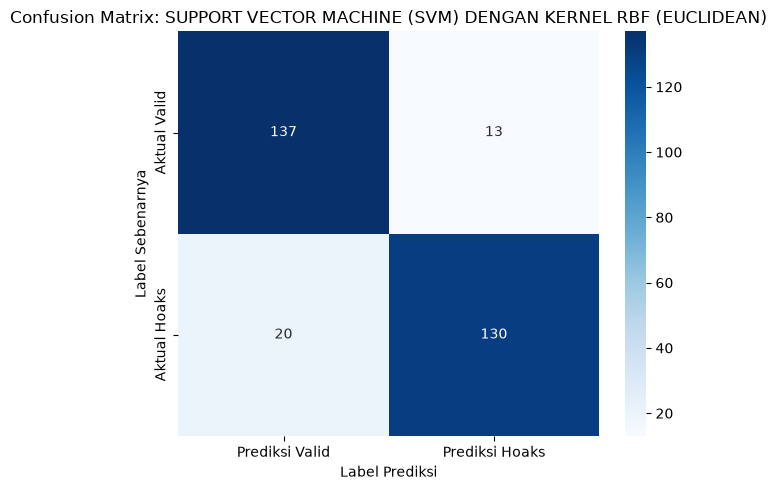

In [6]:
# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: SUPPORT VECTOR MACHINE (SVM) DENGAN KERNEL RBF (EUCLIDEAN)')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()


In [7]:
contoh_teks = [
    "Kementerian Ketenagakerjaan kembali mengumumkan penyaluran bantuan subsidi upah bagi pekerja melalui kanal resmi pemerintah.",
    "Awas bahaya radiasi! Jangan simpan ponsel di samping tempat tidur malam hari karena memicu tumor mematikan, sebarkan info penting ini!"
]

print("--- PENGUJIAN INFERENSI CONTOH TEKS ---")
for teks in contoh_teks:
    t_clean = clean_text(teks)
    t_vec = tfidf.transform([t_clean])
    pred = model.predict(t_vec)[0]
    prob = model.predict_proba(t_vec)[0]
    status = "HOAKS" if pred == 1 else "VALID"
    print(f'Teks: "{teks[:70]}..."')
    print(f'-> Prediksi: {status} (Keyakinan: {prob[pred]*100:.1f}%)\n')


--- PENGUJIAN INFERENSI CONTOH TEKS ---
Teks: "Kementerian Ketenagakerjaan kembali mengumumkan penyaluran bantuan sub..."
-> Prediksi: HOAKS (Keyakinan: 69.9%)

Teks: "Awas bahaya radiasi! Jangan simpan ponsel di samping tempat tidur mala..."
-> Prediksi: VALID (Keyakinan: 97.4%)



### Pembahasan Akademis: SVM Kernel RBF (Euclidean)
1. **Karakteristik Non-Linear**: RBF mampu memisahkan data teks yang batas keputusannya non-linear dengan menggunakan pembobotan berbasis jarak Euclidean Gaussian.
2. **Performa Serupa**: Karena data TF-IDF telah dinormalisasi L2, performa akurasi RBF bersaing ketat dengan Linear (**89,00%**), namun membutuhkan komputasi eksponensial matriks yang sedikit lebih berat (~1,30 detik vs ~0,83 detik).
3. **Waktu Pelatihan**: Waktu komputasi pelatihan RBF sedikit lebih lambat dibanding Linear, namun tetap sangat memadai untuk inferensi real-time.